# 01. Khám phá và Phân tích Dữ liệu (EDA) — Đề tài 12: Phát hiện Giao dịch Thẻ tín dụng Gian lận
**Nhóm 12:** Trần Quang Lương, Nguyễn Văn Hiếu, Vũ Văn Chiến, Nguyễn Giang Nam  
**Mục tiêu notebook:** Kiểm tra cấu trúc, chất lượng dữ liệu, mức độ mất cân bằng lớp, dữ liệu trùng lặp (nguy cơ data leakage), phân phối ngoại lệ của `Amount`, chu kỳ thời gian `Time`, và mức tương quan của các biến PCA `V1..V28` với biến mục tiêu `Class`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_creditcard_data, resolve_data_path

print("Data path:", resolve_data_path())
df = load_creditcard_data()
print("Kích thước dữ liệu:", df.shape)
print("Phân loại kiểu dữ liệu:")
print(df.dtypes.value_counts())
df.head(5)

Data path: D:\creditcard.csv\creditcard.csv
Kích thước dữ liệu: (284807, 31)
Phân loại kiểu dữ liệu:
float64    30
int64       1
Name: count, dtype: int64


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


### Phân tích cấu trúc dữ liệu ban đầu
- Tập dữ liệu gồm **284,807 giao dịch** và **31 cột** (`Time`, `V1`–`V28` là 28 đặc trưng ẩn danh thu được từ phép biến đổi PCA, `Amount`, và nhãn mục tiêu `Class`).
- Toàn bộ 30 đặc trưng đầu vào đều ở dạng `float64`, biến mục tiêu `Class` ở dạng `int64` (`0`: hợp lệ, `1`: gian lận).
- **Ý nghĩa cho bước tiền xử lý:** Không có biến phân loại dạng chuỗi nên không cần One-Hot/Ordinal Encoding, nhưng các thang đo giữa `Time` (hàng trăm nghìn giây), `Amount` (lên tới hơn 25.000) và `V1..V28` khác biệt lớn — rất quan trọng với thuật toán khoảng cách như **K-NN**.

In [2]:
missing_total = int(df.isna().sum().sum())
dup_drop = df.duplicated(keep="first")
dup_count = int(dup_drop.sum())
dup_by_class = df.loc[dup_drop, "Class"].value_counts().to_dict()

print("Tổng số giá trị thiếu (NaN):", missing_total)
print("Số dòng trùng lặp hoàn toàn (cần cân nhắc loại):", dup_count)
print("Phân phối nhãn trong số các dòng trùng lặp bị loại:", dup_by_class)
print("Time tăng đơn điệu?", df["Time"].is_monotonic_increasing)

Tổng số giá trị thiếu (NaN): 0
Số dòng trùng lặp hoàn toàn (cần cân nhắc loại): 1081
Phân phối nhãn trong số các dòng trùng lặp bị loại: {0: 1062, 1: 19}
Time tăng đơn điệu? True


### Nhận xét dữ liệu thiếu, trùng lặp & nguy cơ Data Leakage
- **Dữ liệu thiếu:** **0** giá trị thiếu — dữ liệu đã được làm sạch hoàn toàn về mặt giá trị khuyết.
- **Dữ liệu trùng lặp:** Phát hiện **1,081 dòng trùng lặp hoàn toàn** (trong đó có `1,062` dòng `Class=0` và **`19` dòng `Class=1`**).
- **Nguy cơ rò rỉ dữ liệu (Data Leakage):** Nếu giữ nguyên các dòng trùng lặp rồi chia ngẫu nhiên Train/Test ở Luồng A, một giao dịch gian lận giống hệt nhau có thể nằm ở cả Train lẫn Test khiến mô hình (đặc biệt là **K-NN**) đạt điểm cao giả tạo. Do đó, **Luồng B** sẽ loại bỏ dòng trùng lặp *trước khi chia tập* để đánh giá trung thực khả năng tổng quát hóa.
- **Tính thứ tự thời gian:** Cột `Time` tăng đơn điệu từ `0` đến `172792` giây (~48 giờ).

Class 0: 284,315 (99.8273%)
Class 1: 492 (0.1727%)


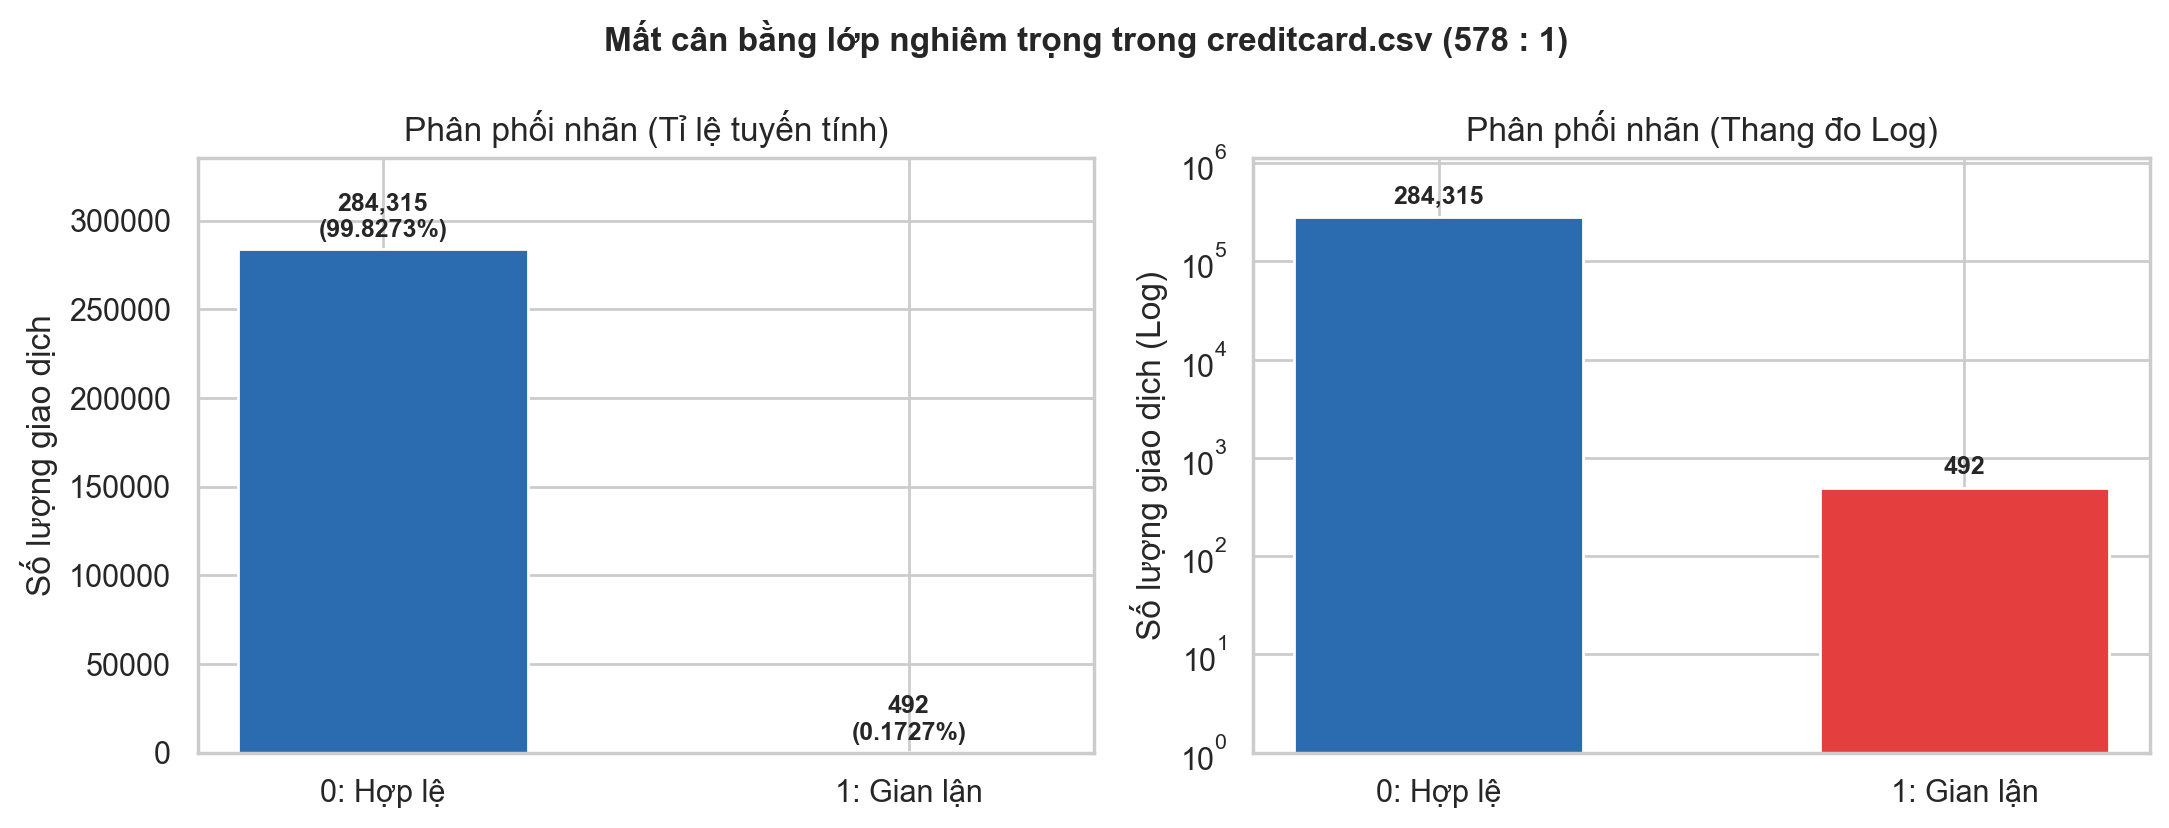

In [3]:
vc = df["Class"].value_counts().sort_index()
vc_pct = df["Class"].value_counts(normalize=True).sort_index() * 100
for k in vc.index:
    print(f"Class {k}: {vc[k]:,} ({vc_pct[k]:.4f}%)")

fig_path = PROJECT_ROOT / "outputs" / "figures" / "eda_class_distribution.png"
if fig_path.is_file():
    display(Image(filename=str(fig_path)))

### Phân tích mất cân bằng lớp
- Lớp `0` (giao dịch hợp lệ) chiếm **284,315 mẫu (99.8273%)**, trong khi lớp `1` (gian lận) chỉ có **492 mẫu (0.1727%)** — tỉ lệ mất cân bằng xấp xỉ **578 : 1**.
- **Hệ quả đánh giá:** Một mô hình tầm thường đoán toàn bộ là `0` vẫn đạt Accuracy **99.83%** nhưng bỏ sót 100% gian lận (`Recall = 0`). Vì vậy nhóm **không dùng Accuracy làm tiêu chí chính**, mà tập trung vào **Precision, Recall, F1-score, PR-AUC** và **Confusion Matrix**.

Thống kê Amount theo Class:
          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      284315.0   88.29  250.11  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.21  256.68  0.0  1.00   9.25  105.89   2125.87

Số giao dịch Amount == 0 theo Class:
Class
0    1798
1      27
Name: count, dtype: int64


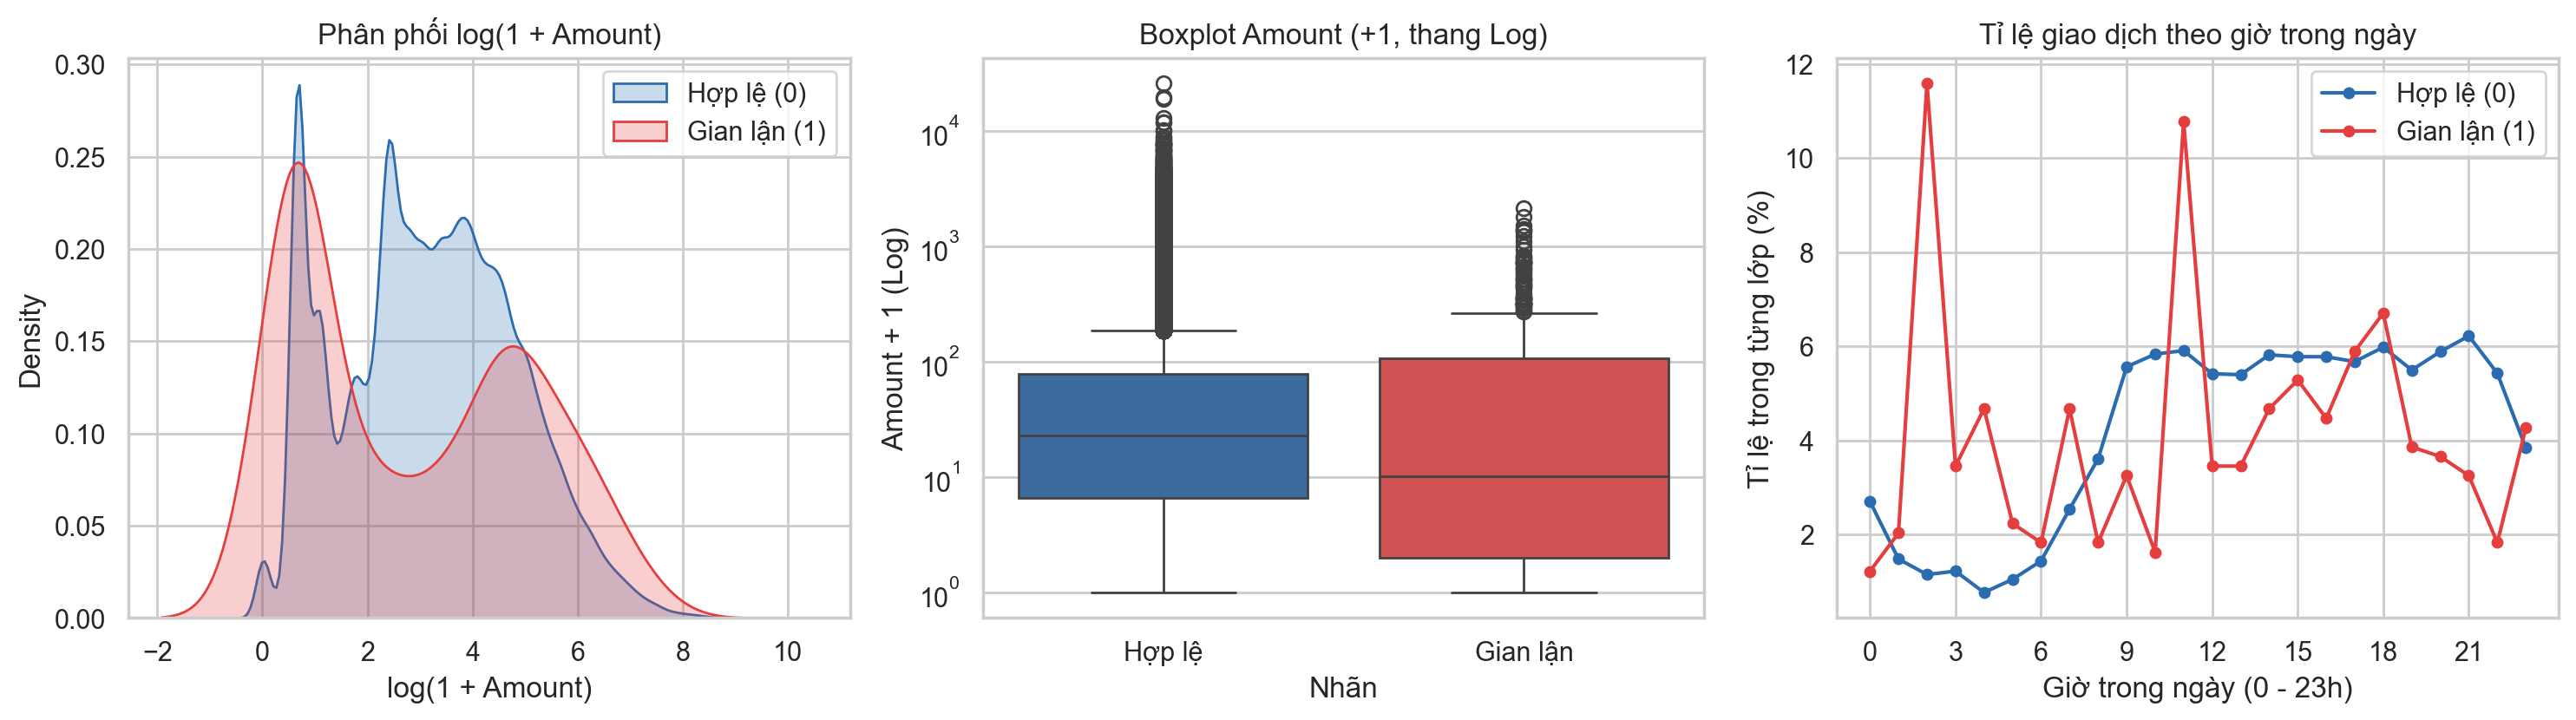

In [4]:
print("Thống kê Amount theo Class:")
print(df.groupby("Class")["Amount"].describe().round(2))
print("\nSố giao dịch Amount == 0 theo Class:")
print(df[df["Amount"] == 0]["Class"].value_counts())

fig_path = PROJECT_ROOT / "outputs" / "figures" / "eda_amount_time_distribution.png"
if fig_path.is_file():
    display(Image(filename=str(fig_path)))

### Phân tích phân phối `Amount` và chu kỳ `Time`
- **Đặc trưng `Amount`:** Lệch phải rất mạnh (overall max `25,691.16`, median `22.00`). Giao dịch gian lận có median thấp hơn (`9.25` so với `22.00`), nhưng giá trị trung bình lại cao hơn (`122.21` so với `88.29`).
- **Tín hiệu `Amount == 0`:** Có `27` / `492` giao dịch gian lận có giá trị `0.00` (**~5.49%**), cao gấp gần **9 lần** tỉ lệ ở giao dịch hợp lệ (`1798` / `284,315` ≈ **0.63%**) — gợi ý tạo đặc trưng `Is_Zero_Amount` ở Luồng B cùng biến đổi `log1p(Amount)` và `RobustScaler` để giảm ảnh hưởng ngoại lệ.
- **Đặc trưng `Time`:** Theo biểu đồ giờ trong ngày, giao dịch hợp lệ tập trung vào ban ngày (`9h–22h`) và giảm sâu vào ban đêm (`0h–6h`), trong khi gian lận xuất hiện đỉnh bất thường vào lúc **~2h sáng** và **~11h trưa**. Vì vậy, thay vì giữ `Time` thô tăng tuyến tính, Luồng B chuyển sang biểu diễn chu kỳ `(Hour_sin, Hour_cos)`.

Top 12 đặc trưng tương quan tuyến tính mạnh nhất với Class:
V17   -0.3265
V14   -0.3025
V12   -0.2606
V10   -0.2169
V16   -0.1965
V3    -0.1930
V7    -0.1873
V11    0.1549
V4     0.1334
V18   -0.1115
V1    -0.1013
V9    -0.0977
Name: Class, dtype: float64


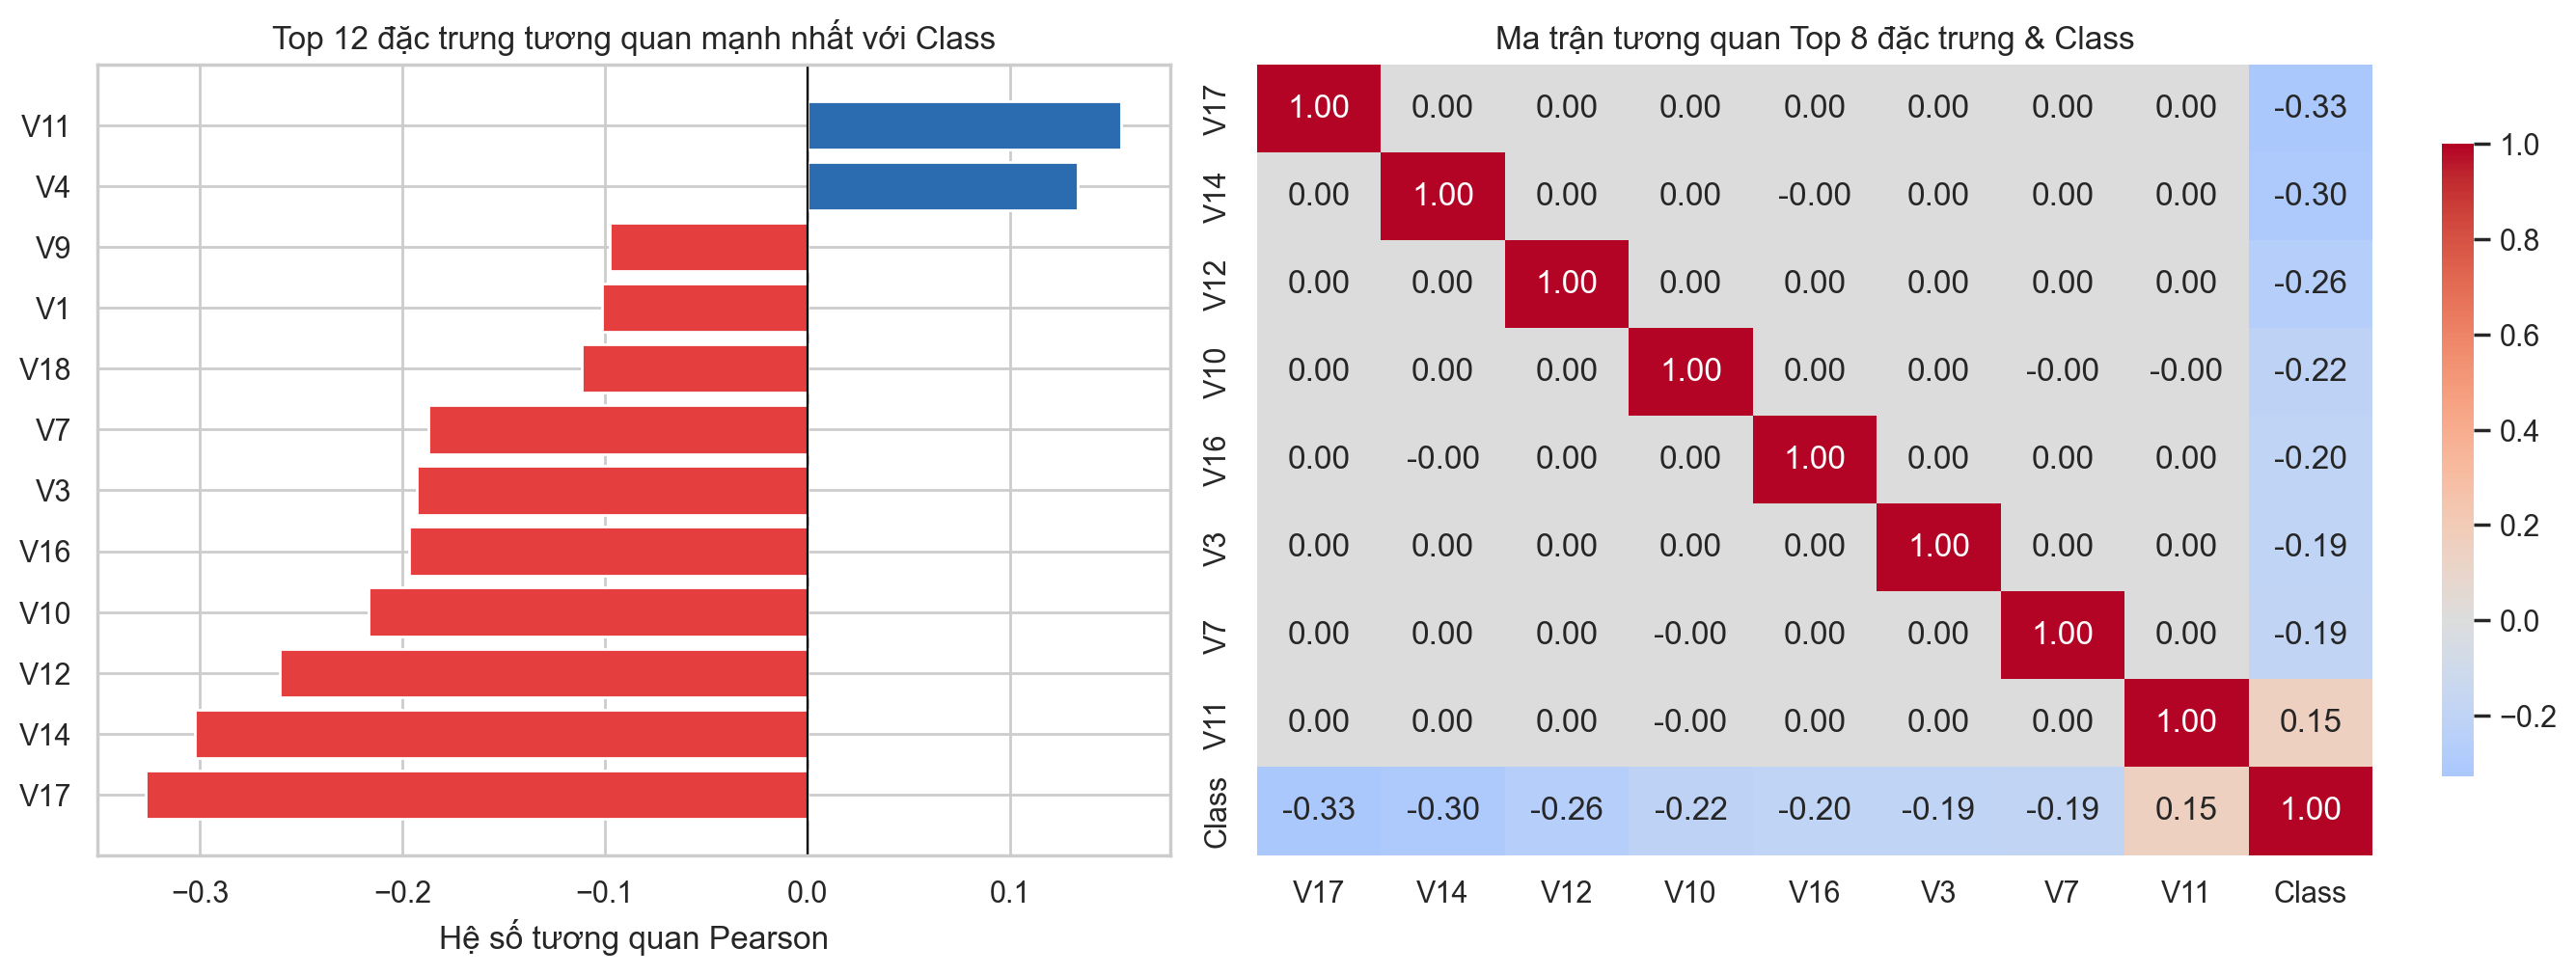

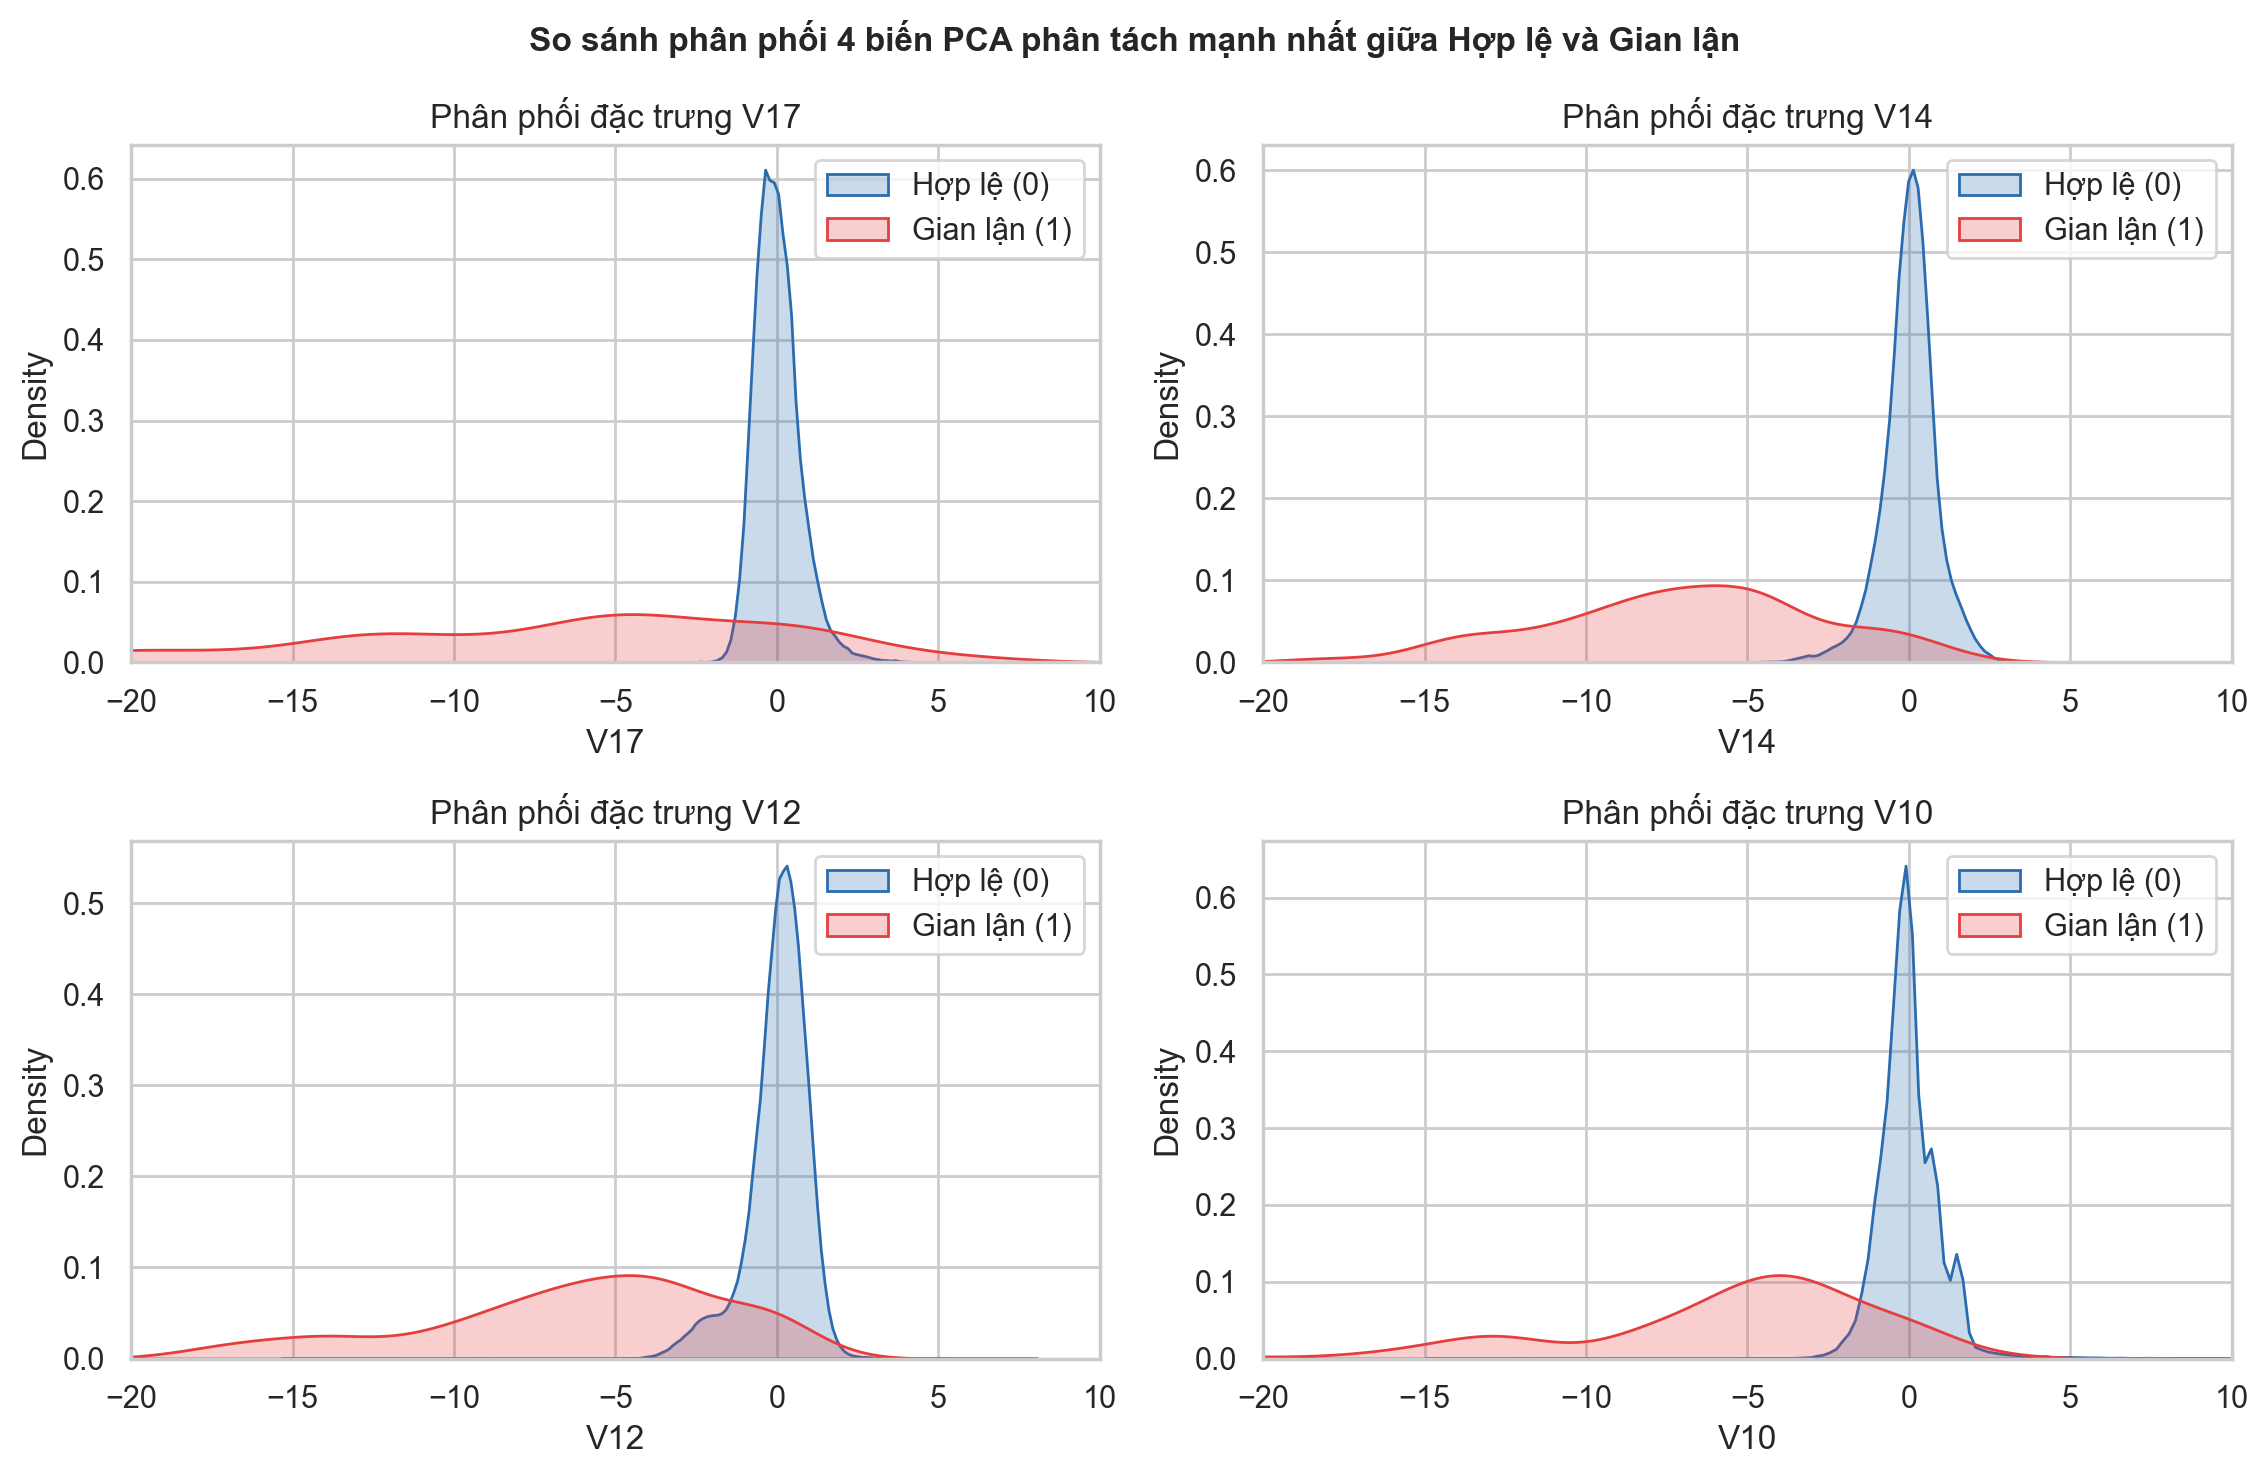

In [5]:
corr = df.corr(numeric_only=True)["Class"].drop("Class")
top_corr = corr.reindex(corr.abs().sort_values(ascending=False).index[:12])
print("Top 12 đặc trưng tương quan tuyến tính mạnh nhất với Class:")
print(top_corr.round(4))

for fname in ["eda_top_correlations.png", "eda_key_features_dist.png"]:
    p = PROJECT_ROOT / "outputs" / "figures" / fname
    if p.is_file():
        display(Image(filename=str(p)))

### Phân tích tương quan và khả năng phân tách của các biến PCA
- Các đặc trưng PCA tương quan mạnh nhất với `Class` là **`V17` (`-0.3265`)**, **`V14` (`-0.3025`)**, **`V12` (`-0.2606`)**, **`V10` (`-0.2169`)** (âm) và **`V11` (`+0.1549`)**, **`V4` (`+0.1334`)** (dương).
- Trên ma trận tương quan giữa 8 biến hàng đầu, hệ số tương quan chéo gần như bằng `0.00` (tính chất trực giao của PCA). Đây là căn cứ giải thích tại sao **Gaussian Naive Bayes** vẫn có thể đạt khả năng xếp hạng (ROC-AUC) đáng kể dù giả định các đặc trưng độc lập có điều kiện, nhưng lại bị hạn chế về Precision vì phân phối của các biến gian lận có đuôi dài lệch mạnh.
- Biểu đồ KDE cho thấy giao dịch gian lận có xu hướng dịch sâu về phía giá trị âm ở `V17, V14, V12, V10`, tuy nhiên vẫn có vùng chồng lấn quanh `0` với giao dịch hợp lệ — đây sẽ là trọng tâm của phần **Phân tích lỗi (Error Analysis)** sau huấn luyện.

---

### Kết luận bước EDA & Định hướng thiết kế Pipeline
1. **Chống Data Leakage:** Chia Train/Val/Test (60/20/20) trước khi `fit` mọi bộ chuẩn hóa; riêng Luồng B loại 1.081 dòng trùng lặp trước khi chia.
2. **Thiết kế Luồng A vs Luồng B:** Luồng A dùng 30 cột gốc + `StandardScaler`; Luồng B dùng `log1p(Amount)`, `Is_Zero_Amount`, `(Hour_sin, Hour_cos)` + `RobustScaler` (và thử nghiệm `PowerTransformer` cho GaussianNB).
3. **Độ đo ưu tiên:** Báo cáo song song `Accuracy`, `Precision`, `Recall`, `F1-score`, `ROC-AUC`, `PR-AUC` và `Confusion Matrix`.